# SolarLoss — protected shading evaluation v2

Retrospective, dataset-aware experiment on checksum-verified La Réunion measurements. The historical notebook remains unchanged. This notebook executes E1–E4 and displays E5 as a source-backed proposal. No causal repair recovery, commercial savings or universal fault diagnosis is inferred.

CPU workflow: ~1.8 GB source cache; weather reads in 500,000-row chunks. Electrical frames retain compact columns; allow several GB RAM. Use Drive caching to avoid repeated downloads. Upload the complete analysis ZIP if the private repository is unavailable in Colab. Run all cells in order. The frozen protocol is read before any protected evaluation. Source files: [Zenodo](https://zenodo.org/records/7291380), [data paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC9800176/), [setup paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC9497466/).

In [1]:
import os, sys, subprocess, zipfile
from pathlib import Path
configured = os.environ.get('SOLARLOSS_ANALYSIS_DIR')
candidates = [Path(configured)] if configured else []
for base in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([base/'analysis', base])
ANALYSIS_DIR = next((p.resolve() for p in candidates if (p/'EXPERIMENT_PROTOCOL_V2.md').exists()), None)
if ANALYSIS_DIR is None:
    from google.colab import files
    uploaded = files.upload()  # Select the complete SolarLoss v2 integration ZIP.
    bundle = next(Path(name) for name in uploaded if name.endswith('.zip'))
    dest = Path('/content/solarloss_v2'); dest.mkdir(exist_ok=True)
    with zipfile.ZipFile(bundle) as z:
        for item in z.infolist():
            target=(dest/item.filename).resolve()
            if dest.resolve() not in target.parents and target!=dest.resolve():
                raise ValueError('Unsafe ZIP path')
        z.extractall(dest)
    ANALYSIS_DIR=dest/'analysis'
subprocess.check_call([sys.executable,'-m','pip','install','-q','-r',str(ANALYSIS_DIR/'requirements-v2.txt')])
sys.path.insert(0,str(ANALYSIS_DIR/'src'))
print('Analysis:',ANALYSIS_DIR)

Analysis: C:\Users\tanej\Documents\Codex\2026-10-10\files-mentioned-by-the-user-solarloss\work\analysis


## Cache and frozen protocol

Drive mounting applies only in Colab. Local execution uses the same real-byte cache through environment variables. `INCLUDE_WEATHER=False` is an explicitly different fallback experiment: its model choice and metrics must not be relabelled as the weather-enabled result.

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    cache_root=Path('/content/drive/MyDrive/solarloss_phase2')
except ImportError:
    cache_root=ANALYSIS_DIR/'data'
DATA_DIR=Path(os.environ.get('SOLARLOSS_DATA_DIR',str(cache_root/'raw')))
RESULTS_DIR=Path(os.environ.get('SOLARLOSS_RESULTS_DIR',str(ANALYSIS_DIR/'results')))
INCLUDE_WEATHER=True
from IPython.display import display, Markdown, Image
display(Markdown((ANALYSIS_DIR/'EXPERIMENT_PROTOCOL_V2.md').read_text(encoding='utf-8')))
print('Source cache:', DATA_DIR)

# Frozen retrospective protocol v2

Design frozen on 2026-10-10 before inspecting v2 protected predictions, thresholds, event detection or effects. This is dataset-aware retrospective design, not untouched prospective evidence. The v1 audit is known. No protected outcome may change the following choices; any later change requires an exploratory revision log.

## E1 populations and boundaries

Checksum verification found 6,594 nominal healthy daylight five-minute bins across 63 observed local days before the first shading label, 2022-02-08 07:11:02 UTC (11:11:02 RET). This establishes availability, not model adequacy. The entire first intervention day and all later days are protected from fitting/selection/calibration. Sort pre-event observed healthy daylight local days. First floor(0.60*N) days train; next days through floor(0.80*N) select the model; remaining days calibrate the detector. Missing calendar days are not invented. Final exact boundaries and stricter quality-filter populations will be recorded in frozen_parameters_v2.json before protected scoring. No future healthy data are used to fit any estimator, envelope or threshold. Later zero-labelled data are a separate stability test and may not influence selection.

## Models and availability

Reuse pinned real dataset and exact one-to-one UTC electrical pairing. Train on nonoverlapping five-minute means with all known zero labels, >=80% elapsed support at observed electrical cadence (nominal 6 seconds; gaps >18 seconds excluded), nonnegative finite AC power and reference >=100 W. Predictors: reference Pg; optional GTI, DTI and TA with >=80% field-specific nominal 1Hz coverage. DTI retains paper Table 1 diffuse tilted semantics; no horizontal reinterpretation. TPV is descriptive only. Never use Fault, target voltage/current, or episode identity as a detector predictor. Unknown labels are never healthy.

Candidates: primary fixed 2.10/2.04 table-arithmetic ratio; sensitivity 2.04/2.09 prose ratio; OLS reference; Huber (epsilon1.35, alpha0.0001, max_iter500) if >=500 training bins; weather OLS if >=500 usable training bins and >=90% selection weather coverage. Selection starts from primary capacity baseline, then OLS, Huber, weather in that order; replace only for >=5% MAE improvement on identical available selection bins. No refit using selection/calibration days. Always report both capacities and weather-versus-OLS comparisons on common populations.

## Detector

Primary: five-minute residual mean >99th percentile of signed healthy calibration means, clipped threshold at zero, for two consecutive eligible windows (10-minute nominal persistence). Availability at confirmation is window end, never its start. Calibrate and score exactly the same window statistic. Predetermined sensitivity: one-minute/two-window and 15-minute/two-window detectors, each with its own calibration quantile; never choose among them from fault results. All run over the full stream without labels, with >=80% elapsed support, no integration across >18s gaps, finite eligible predictors, reference>=100 W. Missing/ineligible windows reset persistence. Predictions must be finite and nonnegative. Reference predictor domain: training 0.5th–99.5th percentiles extended by 10% of their range; this predictor-only support screen is frozen. It is not proof of reference health. No residual clipping at zero before threshold calibration. No monthly test-derived threshold adjustment.

Alarms are contiguous confirmed positive windows, broken by missing or negative windows. Evaluate event recall across all 23 grouped physical episodes and separately adequately covered episodes; detector confirms within episode span with alarm support overlapping a labelled interval. Latency is confirmation minus first label; no early retrospective timestamp. Episodes group nonzero observations separated <=300s; also report unique intervention days and 60/300/900s grouping sensitivity, without changing primary grouping. Classes and misses are descriptive.

False alarms: alarm runs with all supporting windows known healthy divided by evaluated healthy window-hours, separately calibration and later stability periods. Report alert-window fractions and healthy window TN/FP as different units. Mixed-label boundary alarms are unassigned, not forced false positives. Precision only on this labelled window population; episode recall and healthy alert-run counts cannot form an episode precision denominator. Day-block bootstrap (2,000, seed20261010) for healthy rates/calibration and intervention-day recall; dependence between days remains, so intervals are exploratory. No universal accuracy or independent intervention claim.

## E3 known-event effects

Apply frozen coefficients to exact raw pairs; weather predictors are shared five-minute means, explicitly a resolution limitation. Signed residual=expected-observed. Integrate trapezoids at actual elapsed UTC seconds on consecutive original records, both labelled and eligible, 0<dt<=18s; never bridge zero-labelled pauses or unsupported gaps. Integrate positive-only endpoint residuals separately and disclose zero-crossing approximation. Report actual/expected energy, signed deviation and positive-only deviation (kWh), raw labelled support, valid seconds, wall-span and coverage. No interpolation, commercial recovery or finance.

Matched healthy placebos: calibration-only healthy contiguous windows of the event's eligible five-minute count, with mean reference within 20% and mean GTI within 20% when available; require at least five blocks over >=3 days. Match without target residuals, then compare signed Wh/hour and energy conditional on event valid duration. Resample whole placebo local-day means, not rows (2,000 draws). These are model-error comparisons, not true-counterfactual confidence intervals or causal identification. Report per-event descriptive signed percentiles and non-simultaneous error bands; no p-value claims or positive-only-above-zero significance test. Aggregate uncertainty resamples intervention days for mean event signed energy and recall, not independent episodes for total loss. At least one healthy, one valid real event, and a measured unsupported interval are selected under declared demo rule: earliest detected >=80%-covered event; no maximization of loss or accuracy.

## E4 and decisions

Freeze descriptive healthy electrical envelopes from training bins by reference-power decile. Post-prediction compare Va/Ia/Vg/Ig/Fg differences from reference-line measurements to their healthy 2.5–97.5% envelopes. Also nearest healthy training neighbours matching reference Pg (20%), GTI (20%) and TA (5C) if present; summarize per episode and per day, avoiding row-level tests. No universal classifier; no target electrical inputs to the AC detector. Operating voltage is neither Voc nor an IV curve; Ig is coupled to Pg and is not independent diagnostic confirmation. Seasonal/irradiance/inverter confounding and sensor precision remain.

E1 GO if >=500 train bins and >=100 selection/calibration bins over >=10 days each, else LIMIT/unavailable. E2 GO limited to this installation if recall>=80%, healthy alarm runs<=0.05/evaluated hour and later healthy nMAE<=10%; otherwise LIMIT (descriptive detection) or REJECT (unavailable/no separation). These are project gates, not validated safety or deployment criteria. E3 LIMIT even with separated placebo deviations: counterfactual magnitude accuracy is unverified. E4 LIMIT for descriptive evidence, REJECT universal fault diagnosis. E5 specification only, owner approval required for scientific backend semantic changes. No production review artifact exported.


Source cache: C:\Users\tanej\Documents\Codex\2026-10-09\solarloss-scientific-dataset-audit-and-modelling\work\dataset


## Execute the complete evaluation

Downloads are streamed and published sizes/MD5s are verified before processing; SHA256 is also recorded. Whole pre-event local days define separate fitting, model-selection and threshold-calibration populations. Frozen parameters are written before protected scoring. No weather transformation is fitted on later data.

In [3]:
from solarloss_research.evaluation_v2 import run
result=run(DATA_DIR,RESULTS_DIR,ANALYSIS_DIR/'EXPERIMENT_PROTOCOL_V2.md',include_weather=INCLUDE_WEATHER)
print('Finished:',result['verdicts'])

Audit dt1_solar_and_meteorological_measurement.csv


Audit dt2_electrical_production_inverter_1_with_faults.csv


Audit dt3_electrical_production_inverter_2.csv


Streaming weather means


FROZEN weather_assisted_linear {1: 39.66669240543495, 5: 30.48382985953691, 15: 27.439219296437702}


Finished: {'E1': 'GO', 'E2': 'LIMIT', 'E3': 'LIMIT', 'E4': 'LIMIT', 'universal_diagnosis': 'REJECT'}


## Verify processing and scientific mechanics

In [4]:
subprocess.check_call([sys.executable,'-m','pytest',str(ANALYSIS_DIR/'tests'),'-q'])
import json, pandas as pd
audit=json.loads((RESULTS_DIR/'data_quality_report_v2.json').read_text())
frozen=json.loads((RESULTS_DIR/'frozen_parameters_v2.json').read_text())
comparison=json.loads((RESULTS_DIR/'model_comparison_v2.json').read_text())
display(pd.DataFrame(audit['checks'])[['file','bytes','md5','sha256','checksum_matches']])
display(pd.DataFrame({k:{'rows':v['row_count'],'first':v['timestamp_start_utc'],'last':v['timestamp_end_utc'],'median_s':v['interval_seconds']['median'],'duplicates':v['duplicate_timestamp_count']} for k,v in audit['audits'].items()}).T)
display(pd.DataFrame(frozen['populations']).T)
print('Alignment:',audit['alignment'])
print('Protocol SHA256:',result['protocol_sha256'])

,file,bytes,md5,sha256,checksum_matches
0,dt1_solar_and_meteorological_measurement.csv,1541026563,5b1e14695adbae4918bff49840916616,a9536c48abd08cdd85a083fe71f3972abf279816f19121...,True
1,dt2_electrical_production_inverter_1_with_faul...,135034852,b97d75f39d9545578f5ee85733a514be,b93934992191eb25a9d5807db1b6652e62c1a3aa114f21...,True
2,dt3_electrical_production_inverter_2.csv,126216618,c03a8016450adb65a260be7be2fff2ca,703da1d47182f02ed973bff6f9b03573bbcddc059b084d...,True
3,00_metadata_variable.jpg,209622,e0f3296375eb4af0d38add7027f33261,45755d44e3bf77a6f0d6e0a44f3ccfaf738f83f3c75cc8...,True


,rows,first,last,median_s,duplicates
dt1_solar_and_meteorological_measurement.csv,30981240,2021-10-28T12:37:45+00:00,2022-10-31T19:59:58+00:00,1.0,0
dt2_electrical_production_inverter_1_with_faults.csv,1990478,2021-10-01T10:10:02+00:00,2022-10-31T14:10:49+00:00,6.0,0
dt3_electrical_production_inverter_2.csv,1990478,2021-10-01T10:10:02+00:00,2022-10-31T14:10:49+00:00,6.0,0


,bins,days,weather_bins
train,3796,37,2958
selection,1327,13,1322
calibration,1441,13,1441


Alignment: {'target_rows': 1990478, 'reference_rows': 1990478, 'target_unique_timestamps': 1990478, 'reference_unique_timestamps': 1990478, 'exact_common_timestamps': 1990478, 'exact_coverage_of_smaller_stream': 1.0, 'target_unmatched_unique': 0, 'reference_unmatched_unique': 0, 'exact_alignment_only': True}
Protocol SHA256: 457cc47db4989634b2de317e241b7744d47639c50d0c86c73f170b1376df0a4b


## Train, select, calibrate, then evaluate

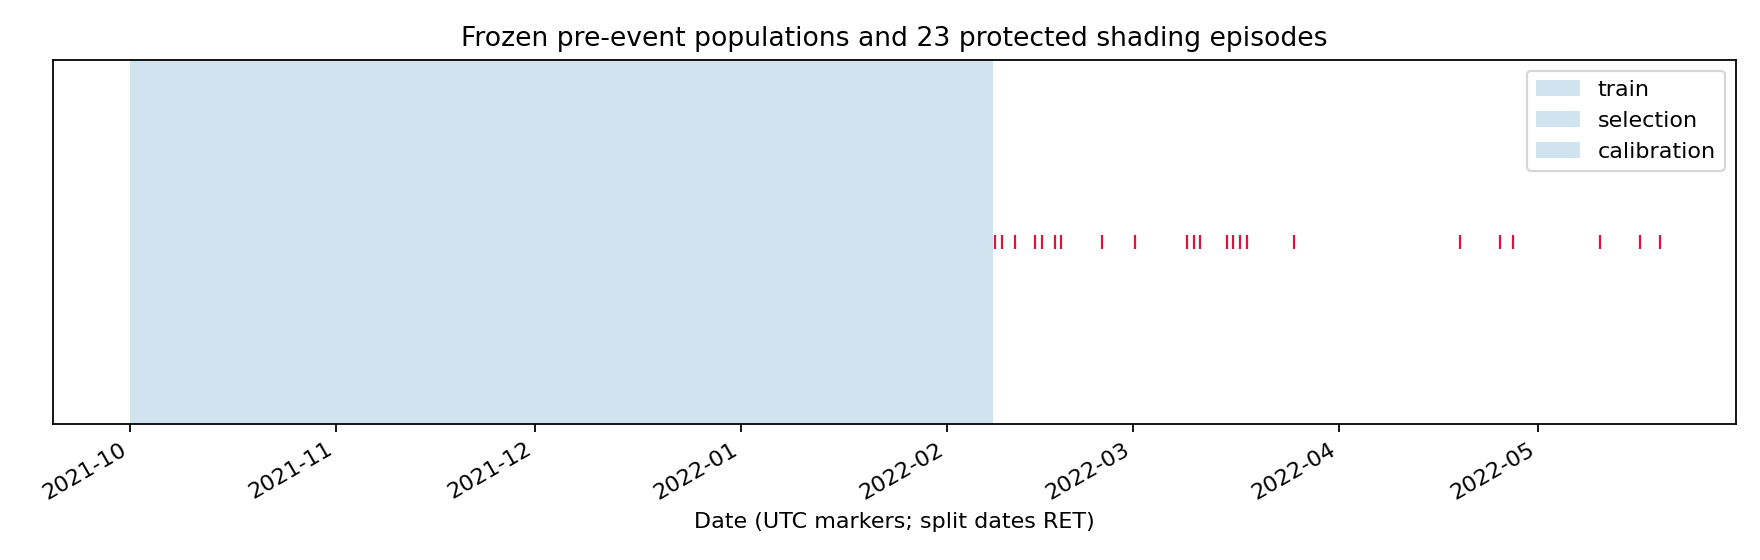

,n,mae_w,nmae,bias_w,rmse_w,mean_observed_w
capacity_table_arithmetic,1327.0,48.708604,0.067043,40.443758,57.338298,726.527833
capacity_paper_prose,1327.0,16.564413,0.022799,0.705927,19.555275,726.527833
calibrated_linear,1327.0,9.076595,0.012493,-0.657484,11.327989,726.527833
huber_reference,1327.0,9.062631,0.012474,-0.289164,11.398913,726.527833
weather_assisted_linear,1322.0,8.260960,0.011405,-0.988156,10.522843,724.345853


,against,common_bins,improvement,passed
calibrated_linear,capacity_table_arithmetic,1327,0.813655,True
huber_reference,calibrated_linear,1327,0.001538,False
weather_assisted_linear,calibrated_linear,1322,0.090677,True


,n,mae_w,nmae,bias_w,rmse_w,mean_observed_w
capacity_table_arithmetic,24320.0,60.583943,0.074736,53.197592,71.052146,810.644761
capacity_paper_prose,24320.0,21.755787,0.026838,8.440757,30.470498,810.644761
calibrated_linear,24320.0,13.574349,0.016745,3.769859,24.448536,810.644761
huber_reference,24320.0,13.699546,0.016900,4.321804,24.584710,810.644761
weather_assisted_linear,24320.0,13.034130,0.016079,5.425057,24.022051,810.644761


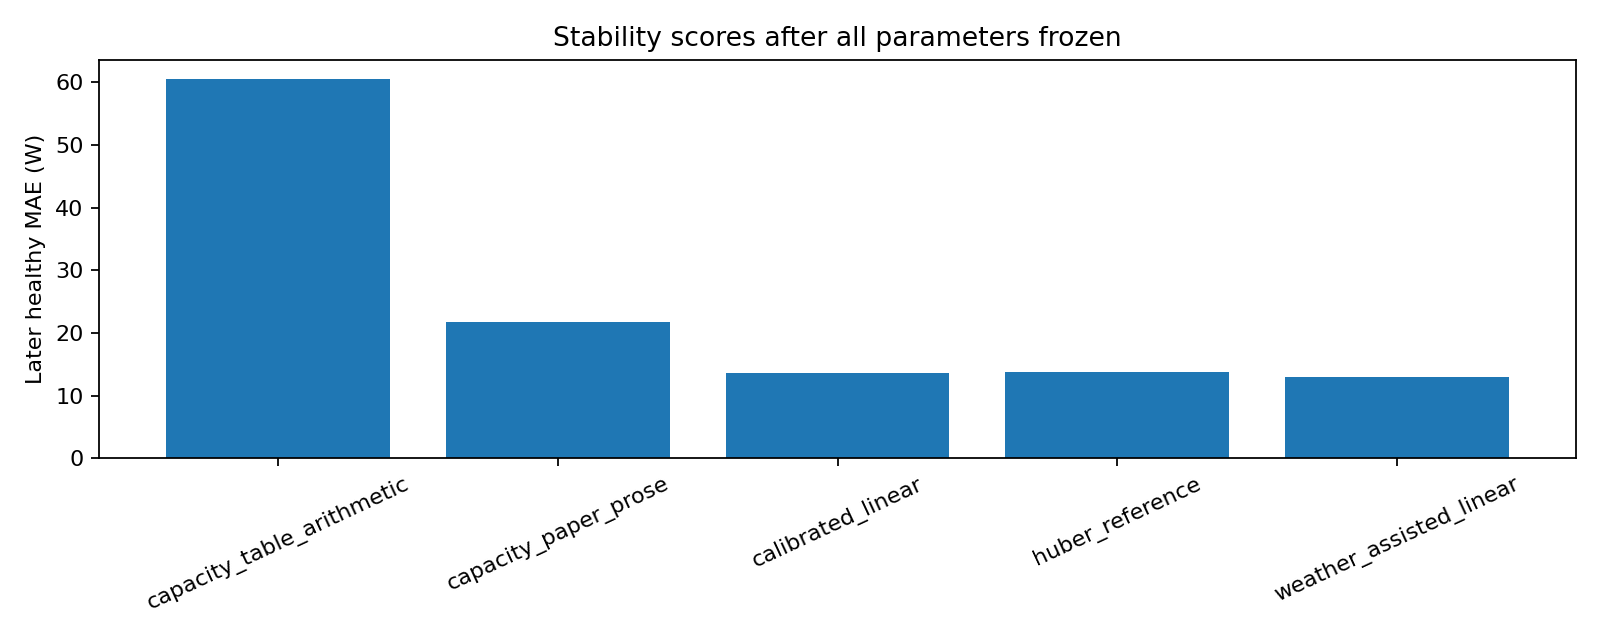

Selected only on early healthy data: weather_assisted_linear
Later healthy stability: {'monthly_healthy_target_reference_median': {'2022-02': 0.9721781611442566, '2022-03': 0.9637251496315002, '2022-04': 0.9598544836044312, '2022-05': 0.9581567645072937, '2022-06': 0.9586339592933655, '2022-07': 0.9602171182632446, '2022-08': 0.9637767672538757, '2022-09': 0.9652353525161743, '2022-10': 0.9661753177642822}, 'relative_median_range': 0.014549165032804012, 'interpretation': 'Target/reference co-stability diagnostic only; inverter2 has no per-row fault ground truth.'}


In [5]:
display(Image(filename=str(RESULTS_DIR/'charts/timeline.png')))
display(pd.DataFrame(comparison['selection_scores']).T)
display(pd.DataFrame(comparison['comparisons']).T)
display(pd.DataFrame(comparison['common_weather_later_scores']).T)
display(Image(filename=str(RESULTS_DIR/'charts/model_comparison.png')))
print('Selected only on early healthy data:',result['selected_model'])
print('Later healthy stability:',result['reference_stability'])

## Automatic detector and physical labels

The detector runs over the full stream with predictor-only availability screens. Fault is read afterwards for evaluation. Recall is by grouped physical episode; healthy false alarms are alert runs per evaluated healthy hour. Window confusion and precision are separate statistics for this labelled dataset, not commercial predictive values.

,event_id,start,labels,detected,latency_seconds,coverage
0,shading_01,2022-02-08 07:11:02+00:00,2.1,True,538.0,0.982765
1,shading_02,2022-02-09 06:58:01+00:00,2.2,True,119.0,0.930047
2,shading_03,2022-02-11 07:05:04+00:00,2.3,True,296.0,0.951190
3,shading_04,2022-02-14 07:30:03+00:00,1.0,True,297.0,1.000000
4,shading_05,2022-02-15 06:50:04+00:00,1.0,True,296.0,1.000000
5,shading_06,2022-02-17 05:20:01+00:00,4.0,True,299.0,0.972413
6,shading_07,2022-02-18 02:24:28+00:00,4.0,True,3032.0,0.938988
7,shading_08,2022-02-24 06:35:00+00:00,3.2,True,3900.0,0.987275
8,shading_09,2022-03-01 05:58:01+00:00,3.2,True,419.0,1.000000
9,shading_10,2022-03-09 04:49:02+00:00,4.0,True,58.0,0.882102


,evaluated_healthy_windows,evaluated_healthy_hours,healthy_alert_runs,false_alarm_runs_per_healthy_hour,false_alarm_rate_day_bootstrap_95pct,healthy_FP_windows,healthy_TN_windows,ambiguous_boundary_alert_windows,alert_window_fraction,healthy_days
1,117010,1746.966111,578,0.330859,"[0.29229479930436447, 0.3714907056853807]",2352,114653,5,0.020101,235
5,22015,1794.506667,153,0.08526,"[0.07187926961388573, 0.09978005359354448]",380,21633,2,0.017261,235
15,6549,1623.927778,37,0.022784,"[0.01572758074877815, 0.030375370501213746]",60,6488,1,0.009162,235


,detected,episodes,healthy_alarm_rate
capacity_table_arithmetic,23.0,23.0,0.108852
capacity_paper_prose,23.0,23.0,0.063312
calibrated_linear,23.0,23.0,0.044430
huber_reference,23.0,23.0,0.045540
weather_assisted_linear,23.0,23.0,0.085260


Window confusion: {'unit': 'eligible labelled 5min windows; any label makes a positive window', 'TP': 1196, 'FN': 167, 'FP': 380, 'TN': 21633, 'precision_on_labelled_windows': 0.7588832487309645, 'ambiguous_boundary_alerts_excluded': 2}
Sensitivity: {'1': {'detected': 23, 'episodes': 23}, '5': {'detected': 23, 'episodes': 23}, '15': {'detected': 23, 'episodes': 23}}
Missed: []
Recall interval (exploratory intervention-day bootstrap): [1.0, 1.0]


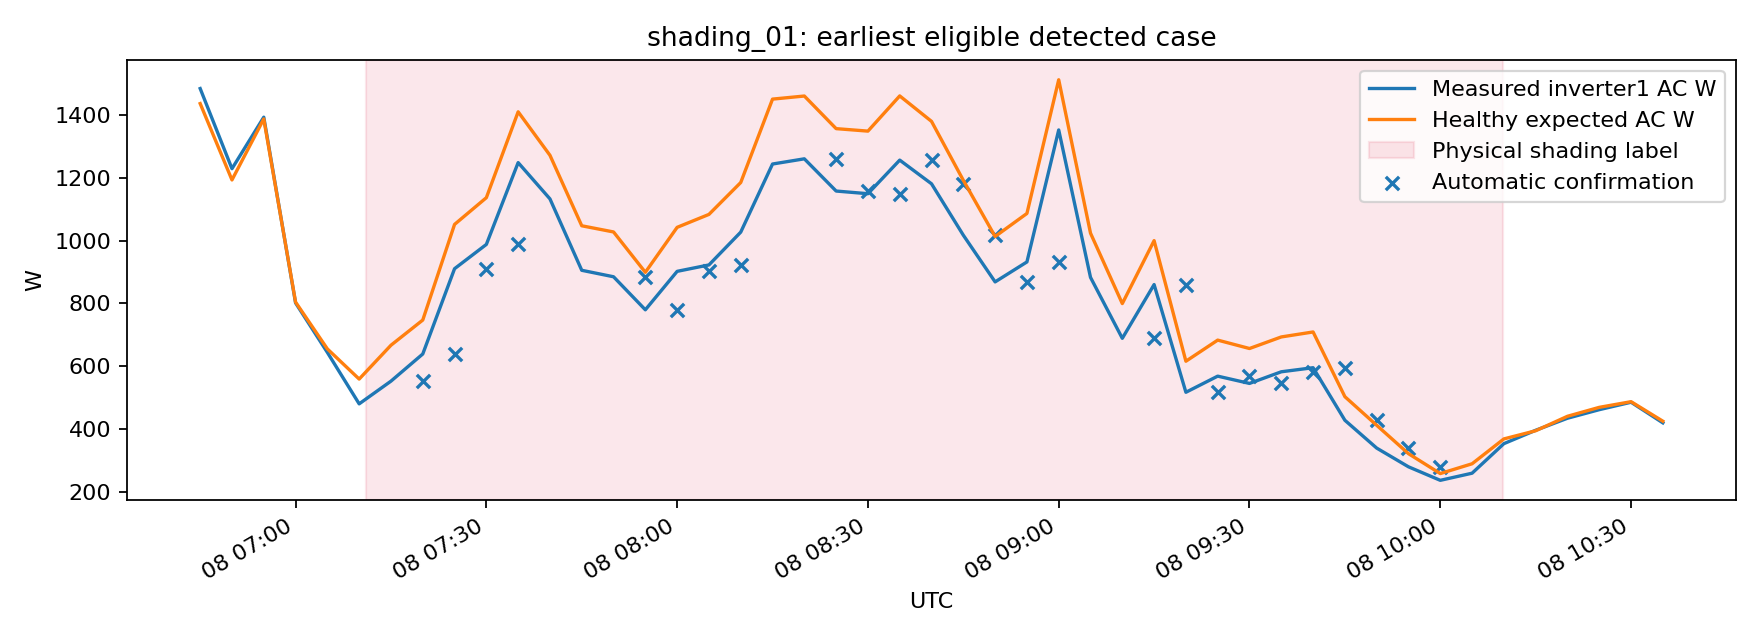

In [6]:
events=pd.read_csv(RESULTS_DIR/'episode_metrics_v2.csv')
display(events[['event_id','start','labels','detected','latency_seconds','coverage']])
display(pd.DataFrame(result['healthy_stability']).T)
display(pd.DataFrame({k:{'detected':v['detected_episodes'],'episodes':v['episode_count'],'healthy_alarm_rate':v['healthy_stability']['false_alarm_runs_per_healthy_hour']} for k,v in result['baseline_detection'].items()}).T)
print('Window confusion:',result['window_confusion'])
print('Sensitivity:',result['window_sensitivity'])
print('Missed:',result['missed_event_ids'])
print('Recall interval (exploratory intervention-day bootstrap):',result['recall_intervention_day_bootstrap_95pct'])
display(Image(filename=str(RESULTS_DIR/'charts/demo_episode.png')))

## Signed energy and model-error comparisons

Integrate only consecutive eligible original records using actual elapsed seconds and gaps <=18s. Signed and positive-only energy are distinct. Positive-only energy cannot establish abnormality. Empirical placebo bands do not identify true unshaded target generation or repair benefits.

,event_id,valid_seconds,coverage,actual_energy_kwh,expected_energy_kwh,signed_energy_kwh,positive_only_kwh
0,shading_01,10549.0,0.982765,2.381649,2.778698,0.397049,0.397126
1,shading_02,11434.0,0.930047,1.723192,2.694930,0.971737,0.971737
2,shading_03,15629.0,0.951190,1.287068,2.581236,1.294169,1.294169
3,shading_04,15092.0,1.000000,0.029526,3.569758,3.540232,3.540232
4,shading_05,17052.0,1.000000,0.114610,5.302060,5.187449,5.187820
5,shading_06,28869.0,0.972413,6.710433,8.567176,1.856742,1.856794
6,shading_07,31858.0,0.938988,6.994355,9.375969,2.381614,2.381642
7,shading_08,11250.0,0.987275,3.046715,3.415872,0.369157,0.375368
8,shading_09,6175.0,1.000000,1.852197,2.171548,0.319351,0.319351
9,shading_10,28379.0,0.882102,4.696011,6.116214,1.420202,1.420595


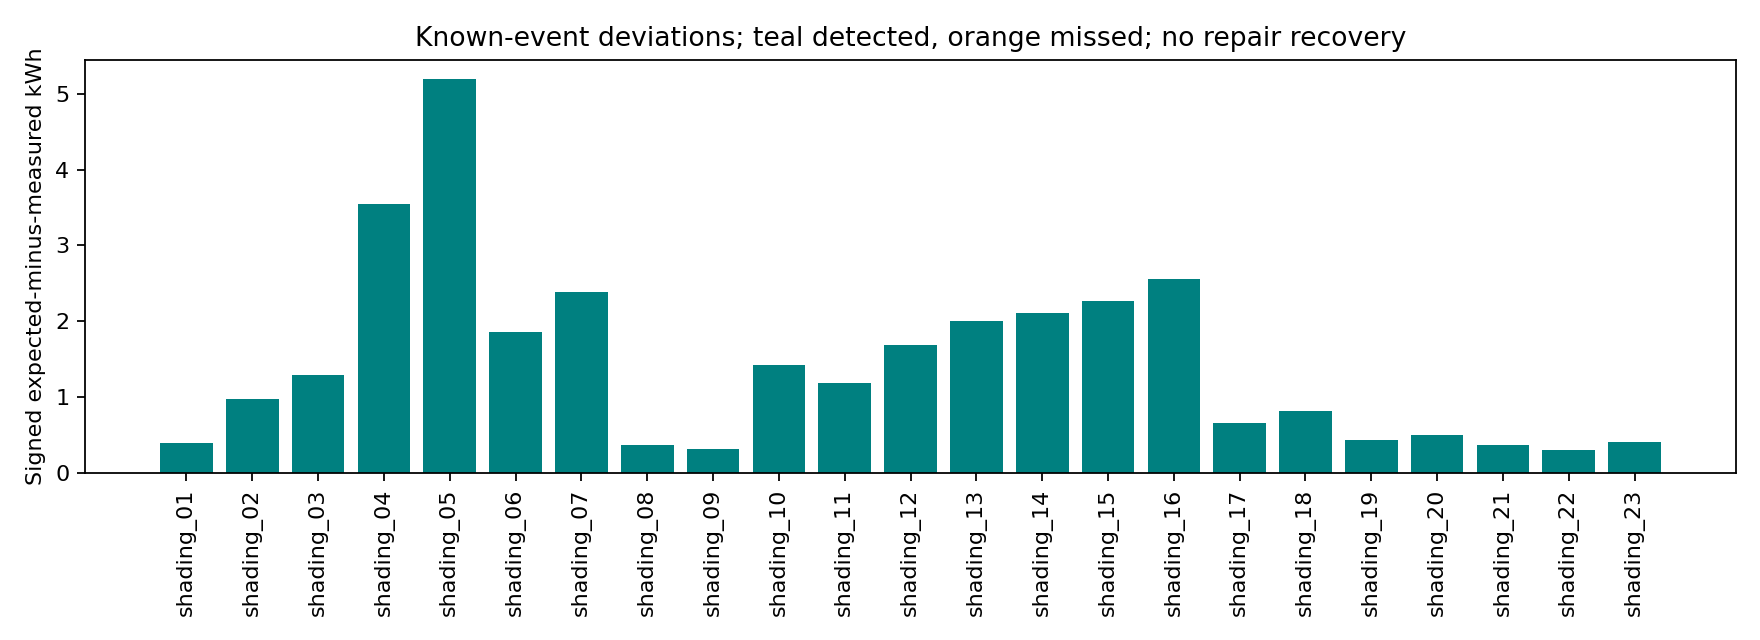

,event_id,status,blocks,days,window_count_per_block,placebo_signed_energy_percentiles_kwh,placebo_mean_signed_w_day_bootstrap_95pct,event_minus_placebo_median_kwh,empirical_model_error_band_kwh,exceeds_placebo_97_5pct,interpretation,reason
0,shading_01,available,10,7,36.0,"[0.0022425079506019157, 0.019188161822347904, ...","[4.7907187393442054, 7.796328063194927]",0.377861,"[0.37014211825708937, 0.3948064694632774]",True,"Non-simultaneous empirical model-error band, N...",NaN
1,shading_02,available,8,7,39.0,"[0.015512414043063997, 0.021707942436885307, 0...","[6.1240754523388174, 8.257601141537572]",0.950029,"[0.9417323657464701, 0.9562250237034924]",True,"Non-simultaneous empirical model-error band, N...",NaN
2,shading_03,unavailable,3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Need >=5 predictor-matched nonoverlapping bloc...
3,shading_04,available,5,5,51.0,"[0.01806521350880793, 0.021983709202401423, 0....","[4.671902074766444, 7.148179894611582]",3.518248,"[3.5075347145331275, 3.522166458162032]",True,"Non-simultaneous empirical model-error band, N...",NaN
4,shading_05,unavailable,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Need >=5 predictor-matched nonoverlapping bloc...
5,shading_06,unavailable,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Need >=5 predictor-matched nonoverlapping bloc...
6,shading_07,unavailable,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Need >=5 predictor-matched nonoverlapping bloc...
7,shading_08,available,9,6,38.0,"[-0.0016373809455126741, 0.016155514186441525,...","[3.2132495658796625, 6.781314027236996]",0.353002,"[0.34640692525022637, 0.37079443191899913]",True,"Non-simultaneous empirical model-error band, N...",NaN
8,shading_09,available,11,6,21.0,"[-0.003488479812145964, 0.005516063002037842, ...","[1.5767994585298464, 5.2114064902600585]",0.313835,"[0.3092208135617026, 0.322839564752125]",True,"Non-simultaneous empirical model-error band, N...",NaN
9,shading_10,unavailable,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Need >=5 predictor-matched nonoverlapping bloc...


Healthy example: {'start': '2022-01-26T03:00:03+00:00', 'end': '2022-01-26T03:59:58+00:00', 'energy': {'available': True, 'valid_seconds': 3595.0, 'interval_count': 719, 'signed_energy_kwh': 0.012293236982942487, 'positive_only_kwh': 0.015578431648304622, 'actual_energy_kwh': 0.3298611111111111, 'expected_energy_kwh': 0.34215434809405365}}
Insufficient-data example: {'start': '2021-12-22T07:00:34+00:00', 'reason': 'Measured source outage: no interpolation and no deviation estimate.', 'end': '2022-01-24T06:20:40+00:00', 'gap_seconds': 2848806.0, 'energy_kwh': None}
Demo event: shading_01


In [7]:
examples=json.loads((RESULTS_DIR/'example_cases_v2.json').read_text())
display(events[['event_id','valid_seconds','coverage','actual_energy_kwh','expected_energy_kwh','signed_energy_kwh','positive_only_kwh']])
display(Image(filename=str(RESULTS_DIR/'charts/event_energy.png')))
display(pd.DataFrame([{ 'event_id':e['event_id'], **e['placebo']} for e in result['episodes']]))
print('Healthy example:',examples['healthy_interval'])
print('Insufficient-data example:',examples['insufficient_data'])
print('Demo event:',result['demo_event_id'])

## Electrical observations and proposed guidance

Operating Va is PV-side voltage, not grid voltage or Voc. Ia is PV current; Ig and Pg are related AC measurements, so Ig is not independent confirmation of power underperformance. Envelopes are trained before shading; matched comparisons are descriptive and remain confounded by operating points and season.

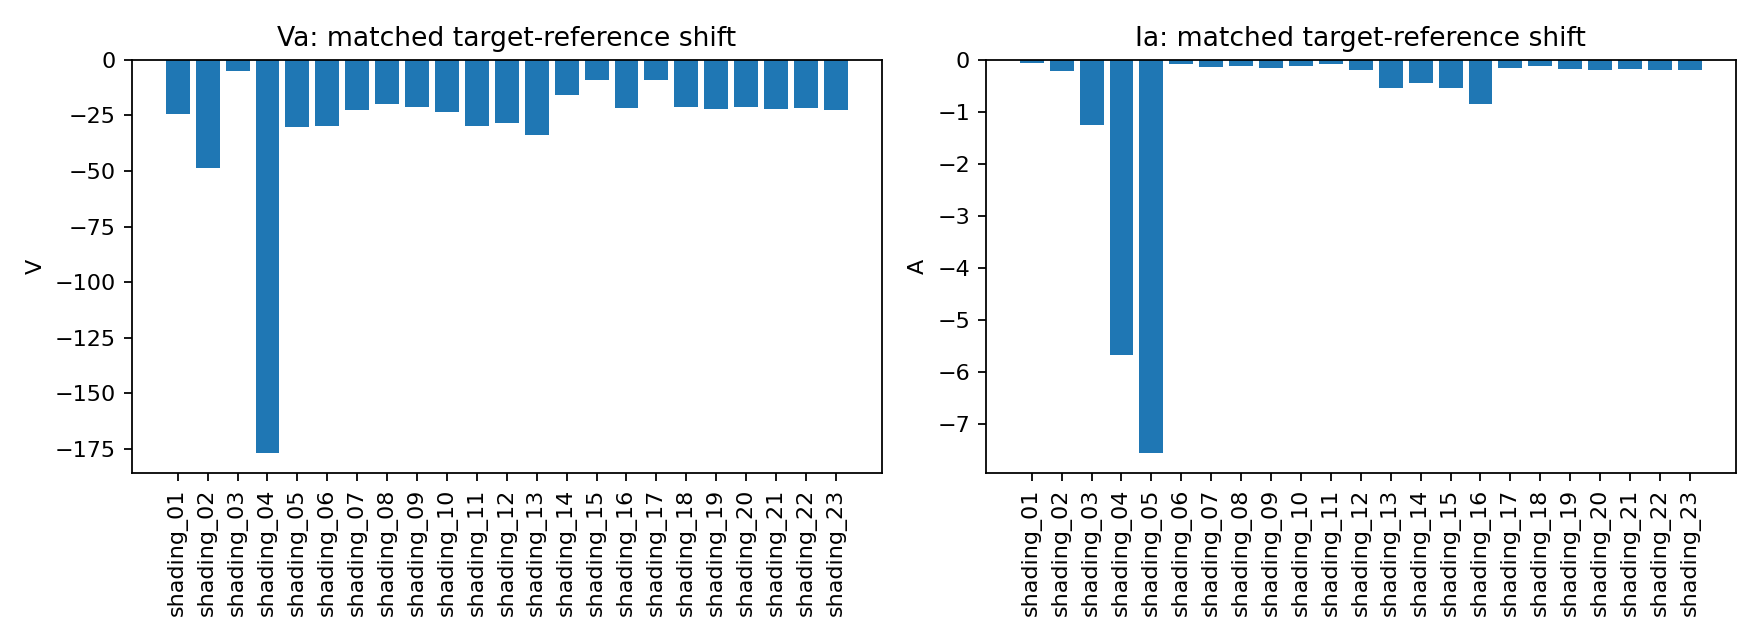

,event_id,signal,unit,valid_five_minute_bins,median_target,median_reference,median_target_minus_reference,outside_healthy_envelope_fraction,matched_bins,matched_median_delta_from_healthy
0,shading_01,Va,V,32,154.616669,175.608337,-22.983330,0.84375,32,-24.545830
1,shading_01,Ia,A,32,5.984167,6.015833,-0.080000,0.09375,32,-0.055000
2,shading_01,Vg,V,32,231.608337,233.274994,-1.599998,0.00000,32,-0.474998
3,shading_01,Ig,A,32,3.671667,4.542500,-0.865000,1.00000,32,-0.644166
4,shading_01,Fg,Hz,32,49.971832,49.999916,-0.032084,0.15625,32,-0.002167
...,...,...,...,...,...,...,...,...,...,...
110,shading_23,Va,V,25,157.270264,177.000000,-21.000000,1.00000,25,-22.408768
111,shading_23,Ia,A,25,7.262163,7.513514,-0.213158,0.24000,25,-0.205608
112,shading_23,Vg,V,25,232.054047,233.567566,-1.405411,0.00000,25,-0.337738
113,shading_23,Ig,A,25,4.526316,5.605263,-1.094594,1.00000,25,-0.865702


# Electrical evidence matrix — E4

All strengths refer to this installation and observed telemetry, not universal fault diagnosis. Read measured per-event comparisons in results/shading_evaluation_v2.json and charts/electrical_observations.png. Five-minute healthy envelopes are trained before the first intervention by reference-Pg decile; matched descriptive comparisons additionally use reference power/GTI within 20% and ambient temperature within 5 C where available. No electrical signal is added to the AC-power detector. Unknown sensor precision and response delays limit interpretations.

| Observable signal | Valid measurements required | Supports | Does not prove | Alternatives | Missing measurements | Technician investigation | Strength |
|---|---|---|---|---|---|---|---|
| Positive signed Pg residual (W) persisting beyond calibration threshold | Exact AC pairs; supported timestamps; frozen predictor domain; weather coverage when used | Lower target production relative to healthy expected model under stated conditions | Shading cause, module damage, actual counterfactual or recoverable energy | Reference drift, temperature, curtailment, clipping, clouds, sensor error | Inverter status, independently verified reference health, intervention outcomes | Yes, to narrow cause; existing log review is a reasonable first step | SUPPORTED for measured comparison; LIMITED causal interpretation |
| Va target/reference departure from healthy envelope (V) | Synchronized PV operating-voltage telemetry, operating inverter, matched reference output/irradiance | Changed PV operating point; adds descriptive information beyond AC power alone | Voc, a full IV curve, defective bypass diode, exact failed module or universal shading classification | MPPT search, temperature, array mismatch, irradiance, grid-connected control state | String-resolved voltage/current, IV sweep, inverter MPPT/status, temperatures at affected modules | Yes; qualified personnel choose any additional tests | LIMITED |
| Ia target/reference departure (A) | Valid PV current, comparable output/irradiance and sensor scale; no outage bridging | DC-current difference under matched conditions | Open string, soiling, insulation fault or a unique cause | Irradiance gradients, operating-voltage movement, sensor bias, array mismatch | String-level current, synchronized local irradiance, inverter state | Yes | LIMITED |
| Ig current (A) with Pg output | Valid grid-current telemetry and grid voltage, synchronized time | AC output observation and consistency check | Independent corroboration of production loss; arc detection | Same power change already represented by Pg; power factor, sensor quantization | Power factor, phase-resolved data, higher-rate waveforms | Only if inconsistency or status evidence warrants it | LIMITED; independent diagnostic gain UNSUPPORTED |
| Vg grid-side voltage (V) | Sensor semantics/precision verified and site/OEM operating limits known | Observed grid-voltage variation | PV-side voltage, grid fault or compliance violation from an arbitrary numerical threshold | Grid regulation, load change, logger artifact, reference sensor difference | Applicable grid code/settings, inverter alarm log, calibrated quality measurements | Qualified professional/utility for grid interpretation | LIMITED |
| Fg grid frequency (Hz) | Valid documented frequency measurements, precision and site settings | Recorded frequency observations | Transient grid-fault exclusion or diagnosis with ~6s sampling | Logger resolution, sampling aliasing, ordinary grid variation | Inverter protection/status and appropriate independent grid-quality record | Qualified professional if status/validated limits indicate | LIMITED observations; diagnostic validation UNSUPPORTED |
| GTI/DTI irradiance (W/m2) | SPN1 sensor exposure/orientation/configuration and >=80% coverage | Environmental comparability and weather features | Irradiance reaching every shaded cell, horizontal DHI, or fault cause | Local shadows on sensor, gradients, calibration, orientation | Cell/module-local irradiance and calibration history | Operator may verify records; physical sensor work follows site plan | SUPPORTED metadata meaning; LIMITED array representativeness |
| TA/TPV temperature (C) | Defined ambient/back-surface sensors, time support, sensor location | Environmental context and temperature confounding | Temperature of every module/cell, hotspot or thermal safety | Sensor placement, attachment and irradiance changes | Thermography and affected-module temperatures | Qualified inspection where evidence warrants | LIMITED |
| Missing/invalid exact pairs or unsupported domain | Audit counts, explicit exclusions and no imputation | Result unavailable in that interval | Zero generation or a physical outage cause | Communications/database failure, power outage, timestamp error | Acquisition logs and verified status | Existing-log investigation first | SUPPORTED unavailability |

The [data paper Tables 1–2](https://pmc.ncbi.nlm.nih.gov/articles/PMC9800176/) separates PV current/voltage from grid current/voltage and calls DTI diffuse tilted irradiance. [Sandia DC Array IV](https://pvpmc.sandia.gov/modeling-guide/3-dc-array-iv/) motivates caution about operating points; it does not validate a diagnosis from this dataset. See INVESTIGATION_GUIDANCE_PROPOSAL.md for bounded sourced candidate checks.

E4 verdict is LIMIT: Va and Ia may describe changes invisible in a single scalar AC residual, but neither envelope departures nor descriptive matching establish incremental held-out diagnosis accuracy. Ig is largely coupled to the AC target. Vg/Fg have no grid-fault ground truth. Reject universal cause classification, module identification and unsafe maintenance prescriptions. Results are grouped by episode/day and no millions-of-independent-rows hypothesis tests are performed.


# Investigation guidance proposal â€” E5

Status: proposed specification only; Rachit reviews scientific wording before integration. No root-cause rules engine, repair directions or diagnosis accuracy is implemented. An anomaly and a physical label are distinct. Every candidate card must carry observed fields/units/timestamps, quality exclusions, a hypothesis, supporting and opposing evidence, next information, qualification constraint, sources, and SUPPORTED/LIMITED/UNSUPPORTED status. Suppress hypothesis cards if their observational inputs are unavailable.

## Candidate cards

| Trigger / observed fact | Hypothesis and support | Evidence against / alternatives | Next information or inspection | Qualification and source |
|---|---|---|---|---|
| Sustained signed AC residual beyond frozen healthy threshold | Production differs from calibrated healthy expectation | Reference drift, curtailment, clipping, temperature and sensor errors can mimic it | Review inverter state/event logs, curtailment settings, timestamps and independently measured irradiance | Operator may review logs; qualified PV professional interprets array tests. [NREL Â§9](https://docs.nlr.gov/docs/fy19osti/73822.pdf) |
| PV-side Va outside matched healthy operating envelope | Operating point changed; mismatch or MPPT behaviour is a candidate | Va is an operating measurement, not Voc; temperature and irradiance also shift voltage | Request inverter MPPT/state logs and array configuration; professional may determine whether an IV measurement is needed | No disconnection or live-testing instructions. [Sandia DC Array IV](https://pvpmc.sandia.gov/modeling-guide/3-dc-array-iv/) |
| Ia differs from healthy envelope under comparable Pg2 and irradiance | DC current differs under the stated conditions | Cloud gradients, operating-point movement, calibration and string availability remain alternatives | Verify irradiance sensor exposure and seek string-resolved current history | Qualified technician for measurements beyond existing telemetry. [Sandia DC Array IV](https://pvpmc.sandia.gov/modeling-guide/3-dc-array-iv/) |
| Vg/Fg depart from site/OEM envelope or simultaneous inverter logs | Grid conditions may affect inverter operation | Isolated sensor spikes or logger limitations can imitate grid events; this dataset does not validate grid-fault classification | Obtain OEM alarm/status records and applicable site grid settings; request utility or professional review | No generic statutory voltage/frequency limits inferred from these data. [NREL Â§Â§4.2,9](https://docs.nlr.gov/docs/fy19osti/73822.pdf) |
| AC residual and DC-envelope changes coincide with visible obstructions | Shading is a candidate consistent with observations | Mismatch, MPPT response or soiling can share signals; telemetry does not locate a damaged module | Request safely obtained timestamped photos and shade history; qualified inspection if indicated | No rooftop access instruction. [IEA PVFS 3-3](https://iea-pvps.org/wp-content/uploads/2025/02/IEA-PVPS-T13-30-2025-PVFS-ANNEX-Degradation-and-Failure.pdf) |
| Persistent reduction and reported contamination | Soiling is a candidate | Shading and aging cannot be excluded; no cleaning intervention outcomes exist here | Request inspection records and an independent soiling measurement; decide on cleaning under the site plan | No automatic cleaning prescription or benefit claim. [NREL Â§5.3](https://docs.nlr.gov/docs/fy19osti/73822.pdf) |
| Missing, invalid or unsupported aligned measurements | Investigation cannot yet support a production conclusion | Logger failure differs from zero generation | Check timestamp configuration, acquisition gaps, units and calibration history before a new assessment | Existing-log review is possible without electrical intervention. [NREL Â§9](https://docs.nlr.gov/docs/fy19osti/73822.pdf) |

These are our bounded design inferences from the cited guidance, not published SolarLoss diagnostic rules. NREL calls for a site safety program, trained personnel and electrical-work controls (Â§8.2). IEA PVFS describes visual/monitoring evidence for shading and the influence of array and inverter design; it does not validate this detector. Sandia explains that array operating current/voltage do not ensure every module operates at its maximum power point. Use that distinction when interpreting Va/Ia.

OEM boundary: the publications identify Energrid/Gridsoft monitoring and TE1500/TE1700 modules, but do not establish a verified inverter model, serial number, firmware or applicable current alarm manual. No manufacturer-specific fault code, threshold or procedure is therefore proposed. Obtain that documentation before activating OEM-dependent cards. The [Delta-T SPN1 manual](https://delta-t.co.uk/wp-content/uploads/dlm_uploads/2017/05/SPN1-UM-4.1.pdf) supports checking sensor orientation/configuration; it does not supply fault diagnoses for the PV inverter.

Implementability: display measured evidence and these bounded candidate checks after owner review. Universal root-cause classification, repair automation and savings remain REJECT. A useful next validation collects independent sites, technician-confirmed faults, inverter status, string telemetry and safe inspection outcomes; separates site/time holdouts; and assesses technician usefulness rather than invented diagnosis accuracy.


# Backend handoff and proposed v0.2 semantics

Status: proposal only; Rachit approves scientific semantics before the backend contract is frozen. No backend/, web/ or infra/ files are changed. No production review artifact, upload or deployment is performed.

The current main backend correctly treats artifacts as producer-supplied precomputed evidence, validates identities and does not run ML. Its v0.1 mandatory numeric energy_deficit cannot express unavailable shading energy. The historical healthy-placebo export remains unchanged for provenance, but should not be displayed as shading loss. Updated research code refuses an unapproved production review export and refuses substituting a healthy placebo when shading is unavailable. V2 research JSONs are intentionally not v0.1 review artifacts.

Identity correction: review_identity(experiment_id) derives review_id='review_'+experiment_id and filename=review_id+'.json'. Exporter uses the artifact's experiment.identifier for both. No date/version independently embedded in another identity. Tests enforce this convention. Private legacy placebo construction is retained only as historical implementation context; the public export path cannot call it for unavailable shading.

## Proposed contract

See contracts/review.schema.v0.2.0.proposed.json for a reviewable draft. It is not installed into the backend. Use distinct metric identifiers for healthy MAE/nMAE/bias, recall, healthy alarm-run rate, signed generation deviation, positive-only generation deviation, observed and expected energy. No metric is named recovered electricity or savings. Every metric identifies its unit, evaluated population, definition and calculation. availability=unavailable requires value=null and a reason; availability=estimated requires a finite numeric value and reason=null. Signed energy may be negative. Positive-only energy cannot be negative and never proves abnormality. Fractions require explicit numerator/denominator with units. No unavailable value may display as zero.

Coverage has distinct valid elapsed seconds, observed labelled support and event wall span. Energy must use raw elapsed-time integration, never the downsampled display series. Uncertainty declares kind: empirical healthy-model-error band versus day-bootstrap interval. It never presents a placebo range as a counterfactual-loss confidence interval. Record group count and dependence limitations; unavailable bounds remain null. Application validation must enforce paired ordered bounds and unique metric identifiers, and reject NaN/Infinity.

Provenance records source hashes, protocol SHA256, code version, coefficients/features, whole-day split boundaries, selection population/rules, frozen thresholds/window sizes/persistence, predictor screens, label use, grouping, counts, retrospective design and exclusions. Electrical evidence carries sensor semantics, measured value/unit, comparison population, requirements, support, non-proof, alternatives and strength. Candidate checks carry observed facts separately from hypotheses, evidence for/against, missing next information, qualification/safety constraints, primary references and proposal/approval status. These are technician investigation prompts, not diagnoses.

## Exact integration work after approval

1. Owner resolves metric definitions, electrical wording and proposed enums. Backend owner adds a versioned v0.2 validator/renderer alongside v0.1 with explicit version dispatch. Retain historical artifacts.
2. Add invariants for filename/review/experiment identity agreement, unique metric identity, null/availability semantics, finite values, numerator/denominator population consistency, ordered uncertainty bounds, chronological series and gap markers.
3. Science exporter produces an owner-approved event-specific artifact under review_<experiment_id>.json, with validated original raw-derived energy and compact display series. Run the existing local backend compatibility tool against the corresponding new version before upload.
4. Frontend shows signed deviation, positive-only deviation and healthy calibration as separate labelled metrics; unavailable values get a reason; physical labels and automatic alarms use different visual marks. Show scope, coverage and uncertainty type. Ig is not independent corroboration of Pg.
5. Infrastructure owner handles existing versioned storage/deployment procedures only after compatibility validation and approvals. This scientific package makes no infrastructure change.

Draft schema tests verify negative signed values, forbidden negative positive-only values, and unavailable-null rules. JSON Schema cannot alone establish scientific validity, authorization, cross-field identity equality or true causal interpretation.


Research files written: C:\Users\tanej\Documents\Codex\2026-10-10\files-mentioned-by-the-user-solarloss\work\analysis\results
Limitations: ['Retrospective dataset-aware redesign; no prospective test.', 'Single installation; day blocks may remain dependent.', 'No inverter2 per-row ground truth or actual unshaded inverter1 counterfactual.', 'Placebo intervals quantify empirical healthy-model error, not causal magnitude accuracy.', 'Raw weather-assisted predictions use 5min environmental means.', 'No maintenance interventions, recovered electricity, diagnosis validation or finance.']


In [8]:
display(Image(filename=str(RESULTS_DIR/'charts/electrical_observations.png')))
display(pd.DataFrame([{'event_id':e['event_id'],'signal':s,**v} for e in result['episodes'] for s,v in e['electrical'].items()]))
for name in ['ELECTRICAL_EVIDENCE_MATRIX.md','INVESTIGATION_GUIDANCE_PROPOSAL.md','SCHEMA_FEEDBACK_V2.md']:
    display(Markdown((ANALYSIS_DIR/name).read_text(encoding='utf-8')))
print('Research files written:', RESULTS_DIR)
print('Limitations:',result['limitations'])

## Reproducibility and integration

Research JSONs, CSV numbers and external charts are reusable. No production v0.1 review artifact is created. Rachit must approve metric semantics and proposed v0.2 contract before backend/frontend integration. Preserve the historical v1 results. See README_V2.md and the executive report for exact populations, verdicts, failure modes and demonstration claims.